<a href="https://colab.research.google.com/github/gsilveiralima/-transformar-registros-t-cnicos-de-varredura-em-um-guia-leg-vel/blob/main/C%C3%B3pia_de_Calculadora_de_Efetivo_Policial.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import math

print("=== CALCULADORA DE EFETIVO POLICIAL ===")
print("Simulação educacional de dimensionamento\n")

try:
    pessoas = int(input("Quantidade de pessoas a abordar: "))
    proporcao = int(input("Policiais por pessoa [2]: ") or "2")
    capacidade = int(input("Capacidade por viatura [4]: ") or "4")
    area = float(input("Área da operação em m² [0]: ") or "0")

    if pessoas < 0 or proporcao <= 0 or capacidade <= 0 or area < 0:
        print("Erro: informe valores válidos e não negativos.")
    else:
        # Cálculo do efetivo
        efetivo_necessario = pessoas * proporcao

        # Cálculo das viaturas (arredondamento para cima)
        viaturas_necessarias = math.ceil(
            efetivo_necessario / capacidade
        )

        # Cálculo da área por policial
        cobertura = (
            area / efetivo_necessario
            if efetivo_necessario > 0 else 0
        )

        print("\n========== RELATÓRIO ==========")
        print(f"Pessoas: {pessoas}")
        print(f"Efetivo calculado: {efetivo_necessario} policiais")
        print(f"Viaturas calculadas: {viaturas_necessarias}")
        print(f"Área por policial: {cobertura:.1f} m²")
        print("===============================")
        print("Resultado exclusivamente didático.")

except ValueError:
    print("Erro: informe apenas valores numéricos válidos.")


=== CALCULADORA DE EFETIVO POLICIAL ===
Simulação educacional de dimensionamento



In [16]:
import math
import csv
import os
import ipywidgets as widgets
from IPython.display import display, clear_output
from google.colab import files
from datetime import datetime

# Elementos da UI
pessoas_input = widgets.IntText(value=10, description='Pessoas:')
proporcao_input = widgets.IntText(value=2, description='Pol/Pessoa:')
capacidade_input = widgets.IntText(value=4, description='Cap./Viatura:')
area_input = widgets.FloatText(value=100.0, description='Área (m²):')

btn_calcular = widgets.Button(description="Calcular", button_style='primary')
btn_exportar = widgets.Button(description="Exportar CSV", button_style='success')
btn_baixar = widgets.Button(description="Baixar CSV", button_style='info')
btn_limpar = widgets.Button(description="Limpar", button_style='warning')
btn_deletar = widgets.Button(description="Apagar Histórico", button_style='danger')
out = widgets.Output()

def calcular_valores():
    # widget.value retorna o valor atual, ou 0 se estiver "vazio" dependendo do widget
    pessoas = pessoas_input.value
    proporcao = proporcao_input.value
    capacidade = capacidade_input.value
    area = area_input.value

    # Validação rigorosa
    if pessoas < 0 or proporcao <= 0 or capacidade <= 0 or area < 0:
        return None

    efetivo = pessoas * proporcao
    viaturas = math.ceil(efetivo / capacidade)
    cobertura = (area / efetivo) if efetivo > 0 else 0

    return {
        'Pessoas': pessoas,
        'Proporcao': proporcao,
        'Capacidade': capacidade,
        'Area': area,
        'Efetivo': efetivo,
        'Viaturas': viaturas,
        'Cobertura': cobertura
    }

def calcular(b):
    with out:
        clear_output()
        resultados = calcular_valores()

        if not resultados:
            print("❌ Erro: Por favor, informe valores válidos. (Pessoas >= 0, Proporção > 0, Capacidade > 0, Área >= 0)")
        else:
            print("\n========== RELATÓRIO ==========")
            print(f"Pessoas: {resultados['Pessoas']}")
            print(f"Efetivo calculado: {resultados['Efetivo']} policiais")
            print(f"Viaturas calculadas: {resultados['Viaturas']}")
            print(f"Área por policial: {resultados['Cobertura']:.1f} m²")
            print("===============================")
            print("Resultado exclusivamente didático.")

def exportar(b):
    with out:
        resultados = calcular_valores()
        if not resultados:
            clear_output()
            print("❌ Erro ao exportar: Validação falhou! Verifique se os campos estão preenchidos com valores válidos.")
            return

        filename = 'resultados_calculo.csv'
        file_exists = os.path.exists(filename)
        agora = datetime.now().strftime("%Y-%m-%d %H:%M:%S")

        # Abrir em modo 'a' (append) para adicionar ao histórico
        with open(filename, mode='a', newline='', encoding='utf-8') as f:
            writer = csv.writer(f)
            # Cabeçalho apenas se o arquivo não existir
            if not file_exists:
                writer.writerow(['Data_Hora', 'Pessoas', 'Proporcao_Pol_Pessoa', 'Capacidade_Viatura', 'Area', 'Efetivo_Calculado', 'Viaturas_Calculadas', 'Area_por_Policial'])

            # Dados
            writer.writerow([
                agora,
                resultados['Pessoas'],
                resultados['Proporcao'],
                resultados['Capacidade'],
                resultados['Area'],
                resultados['Efetivo'],
                resultados['Viaturas'],
                round(resultados['Cobertura'], 2)
            ])
        print(f"\n✅ Dados adicionados com sucesso ao histórico no arquivo: {filename}")

def baixar(b):
    with out:
        filename = 'resultados_calculo.csv'
        if os.path.exists(filename):
            print(f"\n⬇️ Iniciando o download de {filename}...")
            files.download(filename)
        else:
            clear_output()
            print("❌ Erro: O arquivo CSV ainda não existe. Por favor, exporte os dados primeiro.")

def limpar(b):
    pessoas_input.value = 10
    proporcao_input.value = 2
    capacidade_input.value = 4
    area_input.value = 100.0
    with out:
        clear_output()

def deletar_historico(b):
    with out:
        filename = 'resultados_calculo.csv'
        if os.path.exists(filename):
            os.remove(filename)
            clear_output()
            print(f"🗑️ Histórico ({filename}) apagado com sucesso! Um novo arquivo será criado na próxima exportação.")
        else:
            clear_output()
            print("ℹ️ O histórico já está vazio (o arquivo CSV não existe).")

btn_calcular.on_click(calcular)
btn_exportar.on_click(exportar)
btn_baixar.on_click(baixar)
btn_limpar.on_click(limpar)
btn_deletar.on_click(deletar_historico)

# Layout
botoes = widgets.HBox([btn_calcular, btn_exportar, btn_baixar, btn_limpar, btn_deletar])
ui = widgets.VBox([widgets.HTML("<h3>Calculadora de Efetivo Policial</h3>"),
                   pessoas_input, proporcao_input, capacidade_input, area_input,
                   botoes, out])
display(ui)

In [6]:
import IPython
display(IPython.display.HTML(filename='/content/calculadora_efetivo_dupla_checagem.html'))

In [20]:
import pandas as pd
import os

# Caminho do arquivo de histórico
filename = 'resultados_calculo.csv'

if os.path.exists(filename):
    # Carrega o CSV usando pandas
    df = pd.read_csv(filename)
    print(f"Exibindo as primeiras linhas do histórico ({filename}):")
    # Exibe as primeiras 5 linhas de forma formatada no Colab
    display(df.head())
else:
    print(f"O arquivo '{filename}' ainda não existe. Por favor, exporte alguns dados na calculadora primeiro.")

Exibindo as primeiras linhas do histórico (resultados_calculo.csv):


,Pessoas,Proporcao_Pol_Pessoa,Capacidade_Viatura,Area,Efetivo_Calculado,Viaturas_Calculadas,Area_por_Policial
0,10,2,4,100.0,20,5,5.0


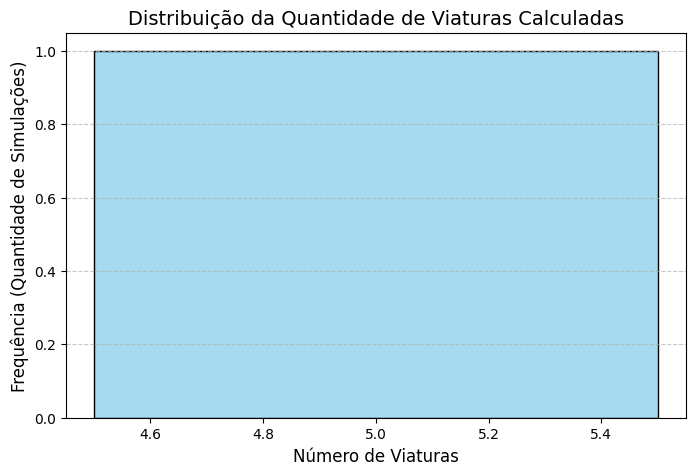

In [24]:
import seaborn as sns
import matplotlib.pyplot as plt

# Verifica se o DataFrame 'df' já está carregado na memória
if 'df' in locals() and not df.empty:
    plt.figure(figsize=(8, 5))

    # Cria um histograma para valores discretos
    sns.histplot(data=df, x='Viaturas_Calculadas', discrete=True, color='skyblue', edgecolor='black')

    # Configurações de título e rótulos
    plt.title('Distribuição da Quantidade de Viaturas Calculadas', fontsize=14)
    plt.xlabel('Número de Viaturas', fontsize=12)
    plt.ylabel('Frequência (Quantidade de Simulações)', fontsize=12)

    # Adiciona uma grade no eixo Y para facilitar a leitura
    plt.grid(axis='y', linestyle='--', alpha=0.7)

    # Exibe o gráfico
    plt.show()
else:
    print("O DataFrame 'df' está vazio ou não foi carregado. Certifique-se de executar a célula anterior e de ter dados no histórico.")

In [25]:
# Verifica se o DataFrame 'df' já está carregado na memória
if 'df' in locals() and not df.empty:
    media = df['Viaturas_Calculadas'].mean()
    desvio_padrao = df['Viaturas_Calculadas'].std()

    print("=== ESTATÍSTICAS: VIATURAS CALCULADAS ===")
    print(f"Média: {media:.2f}")

    # Trata a exibição se houver apenas 1 registro (desvio padrão será NaN)
    if pd.isna(desvio_padrao):
        print("Desvio Padrão: NaN (É necessário mais de 1 registro)")
    else:
        print(f"Desvio Padrão: {desvio_padrao:.2f}")
else:
    print("O DataFrame 'df' está vazio ou não foi carregado.")

=== ESTATÍSTICAS: VIATURAS CALCULADAS ===
Média: 5.00
Desvio Padrão: NaN (É necessário mais de 1 registro)


In [26]:
import pandas as pd
import os

filename = 'resultados_calculo.csv'

if os.path.exists(filename):
    # Carregando o arquivo com pandas
    df_analise = pd.read_csv(filename)

    print("=== INFORMAÇÕES DO DATASET ===")
    # info() mostra os tipos de dados, quantidade de colunas e se há valores nulos
    df_analise.info()

    print("\n=== RESUMO ESTATÍSTICO ===")
    # describe() calcula contagem, média, desvio padrão, mínimo, máximo e quartis
    display(df_analise.describe())
else:
    print(f"O arquivo '{filename}' não foi encontrado. Exporte os dados na calculadora primeiro.")

=== INFORMAÇÕES DO DATASET ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1 entries, 0 to 0
Data columns (total 7 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Pessoas               1 non-null      int64  
 1   Proporcao_Pol_Pessoa  1 non-null      int64  
 2   Capacidade_Viatura    1 non-null      int64  
 3   Area                  1 non-null      float64
 4   Efetivo_Calculado     1 non-null      int64  
 5   Viaturas_Calculadas   1 non-null      int64  
 6   Area_por_Policial     1 non-null      float64
dtypes: float64(2), int64(5)
memory usage: 188.0 bytes

=== RESUMO ESTATÍSTICO ===


,Pessoas,Proporcao_Pol_Pessoa,Capacidade_Viatura,Area,Efetivo_Calculado,Viaturas_Calculadas,Area_por_Policial
count,1.0,1.0,1.0,1.0,1.0,1.0,1.0
mean,10.0,2.0,4.0,100.0,20.0,5.0,5.0
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,10.0,2.0,4.0,100.0,20.0,5.0,5.0
25%,10.0,2.0,4.0,100.0,20.0,5.0,5.0
50%,10.0,2.0,4.0,100.0,20.0,5.0,5.0
75%,10.0,2.0,4.0,100.0,20.0,5.0,5.0
max,10.0,2.0,4.0,100.0,20.0,5.0,5.0
